# Grayscale to Binary Image Conversion (NumPy Only)
**Objective:** Convert a grayscale image into a binary image (`0` and `1` / `255`) purely using **NumPy** via:
1. **Global Manual Thresholding** ($T = 128$ or $0.5$)
2. **Otsu's Automatic Thresholding** (maximizing inter-class variance $\sigma_B^2(t)$)

### Mathematical Formulation
$$g(x, y) = \begin{cases} 1, & \text{if } f(x, y) \ge T \\ 0, & \text{if } f(x, y) < T \end{cases}$$

Manual Threshold : 128
Otsu's Threshold : 114


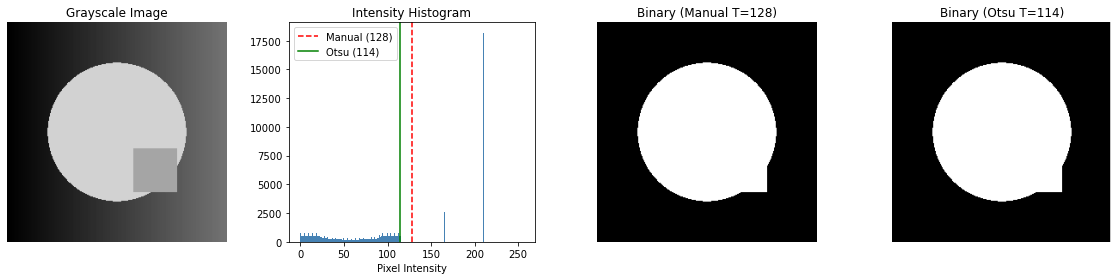

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a sample 256x256 grayscale image (values in [0, 255], uint8)
N = 256
x = np.linspace(0, 255, N, dtype=np.uint8)
gradient_bg = np.tile(x, (N, 1))  # Smooth illumination gradient

X, Y = np.meshgrid(np.linspace(-1, 1, N), np.linspace(-1, 1, N))
gray_img = (gradient_bg * 0.45).astype(np.uint8)
gray_img[(X**2 + Y**2) < 0.4] = 210                                   # Bright circle
gray_img[(np.abs(X - 0.35) < 0.2) & (np.abs(Y - 0.35) < 0.2)] = 165   # Medium-bright square

# 2. Method A: Global Manual Thresholding
def global_threshold(image: np.ndarray, thresh: int = 128) -> np.ndarray:
    return (image >= thresh).astype(np.uint8) * 255

# 3. Method B: Otsu's Automatic Thresholding (Pure NumPy)
def otsu_threshold(image: np.ndarray):
    # Compute 256-bin histogram and probabilities
    hist, _ = np.histogram(image.ravel(), bins=256, range=(0, 256))
    prob = hist.astype(np.float64) / image.size
    bins = np.arange(256)

    # Cumulative weights (w0, w1) and cumulative means
    w0 = np.cumsum(prob)
    w1 = 1.0 - w0
    mean_total = np.sum(bins * prob)
    mean0 = np.cumsum(bins * prob) / (w0 + 1e-12)
    mean1 = (mean_total - np.cumsum(bins * prob)) / (w1 + 1e-12)

    # Between-class variance: sigma_B^2 = w0 * w1 * (mean0 - mean1)^2
    between_class_var = w0 * w1 * ((mean0 - mean1) ** 2)
    optimal_thresh = int(np.argmax(between_class_var))

    binary = (image >= optimal_thresh).astype(np.uint8) * 255
    return binary, optimal_thresh

binary_manual = global_threshold(gray_img, thresh=128)
binary_otsu, best_t = otsu_threshold(gray_img)

print(f"Manual Threshold : 128")
print(f"Otsu's Threshold : {best_t}")

# 4. Visualize Grayscale Input, Histogram, and Binary Outputs
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Grayscale Image")
axes[0].axis("off")

axes[1].hist(gray_img.ravel(), bins=256, range=(0, 256), color="steelblue")
axes[1].axvline(128, color="red", linestyle="--", label="Manual (128)")
axes[1].axvline(best_t, color="green", linestyle="-", label=f"Otsu ({best_t})")
axes[1].set_title("Intensity Histogram")
axes[1].set_xlabel("Pixel Intensity")
axes[1].legend()

axes[2].imshow(binary_manual, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Binary (Manual T=128)")
axes[2].axis("off")

axes[3].imshow(binary_otsu, cmap="gray", vmin=0, vmax=255)
axes[3].set_title(f"Binary (Otsu T={best_t})")
axes[3].axis("off")

plt.tight_layout()
plt.show()